### **Praktikum - Text Classification**

Nama    : Laura Aurelia 

NIM     : 42324027 

Prodi   : D3 Teknologi Informasi 

In [1]:
import pandas as pd
import numpy as np
import re
import string
from nltk.tokenize import word_tokenize
from nltk.stem import WordNetLemmatizer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

Pada bagian ini saya memanggil semua library yang dibutuhkan. Pandas dan numpy dipakai untuk mengolah data, re dan string untuk membersihkan teks, NLTK untuk memecah kalimat menjadi kata dan mengubah kata ke bentuk dasarnya. Dari scikit-learn dipakai TfidfVectorizer untuk mengubah teks menjadi angka, KMeans untuk mengelompokkan data, dan PCA untuk memperkecil dimensi data supaya bisa digambar. Terakhir matplotlib dipakai untuk menampilkan grafik. Bagian ini tidak menghasilkan output karena hanya memanggil library.

In [8]:
file_path = "tmdb_5000_movies.csv"
df = pd.read_csv(file_path)

df = df.rename(columns={'overview': 'text'})
df = df.dropna(subset=['text'])

Dataset dibaca dari file Text.csv dan berisi 5572 pesan dengan dua kolom. Kolom Message saya ganti namanya menjadi text supaya lebih mudah dipanggil di langkah berikutnya. Berbeda dengan praktikum sebelumnya, di sini saya tidak memakai label ham atau spam sama sekali. Yang dipakai hanya isi pesannya, karena klasterisasi adalah unsupervised learning, yaitu komputer mengelompokkan data sendiri berdasarkan kemiripan tanpa diberi jawaban.

In [ ]:
df

,budget,genres,homepage,id,keywords,original_language,original_title,text,popularity,production_companies,production_countries,release_date,revenue,runtime,spoken_languages,status,tagline,title,vote_average,vote_count
0,237000000,"[{""id"": 28, ""name"": ""Action""}, {""id"": 12, ""nam...",http://www.avatarmovie.com/,19995,"[{""id"": 1463, ""name"": ""culture clash""}, {""id"":...",en,Avatar,"In the 22nd century, a paraplegic Marine is di...",150.437577,"[{""name"": ""Ingenious Film Partners"", ""id"": 289...","[{""iso_3166_1"": ""US"", ""name"": ""United States o...",2009-12-10,2787965087,162.0,"[{""iso_639_1"": ""en"", ""name"": ""English""}, {""iso...",Released,Enter the World of Pandora.,Avatar,7.2,11800
1,300000000,"[{""id"": 12, ""name"": ""Adventure""}, {""id"": 14, ""...",http://disney.go.com/disneypictures/pirates/,285,"[{""id"": 270, ""name"": ""ocean""}, {""id"": 726, ""na...",en,Pirates of the Caribbean: At World's End,"Captain Barbossa, long believed to be dead, ha...",139.082615,"[{""name"": ""Walt Disney Pictures"", ""id"": 2}, {""...","[{""iso_3166_1"": ""US"", ""name"": ""United States o...",2007-05-19,961000000,169.0,"[{""iso_639_1"": ""en"", ""name"": ""English""}]",Released,"At the end of the world, the adventure begins.",Pirates of the Caribbean: At World's End,6.9,4500
2,245000000,"[{""id"": 28, ""name"": ""Action""}, {""id"": 12, ""nam...",http://www.sonypictures.com/movies/spectre/,206647,"[{""id"": 470, ""name"": ""spy""}, {""id"": 818, ""name...",en,Spectre,A cryptic message from Bond’s past sends him o...,107.376788,"[{""name"": ""Columbia Pictures"", ""id"": 5}, {""nam...","[{""iso_3166_1"": ""GB"", ""name"": ""United Kingdom""...",2015-10-26,880674609,148.0,"[{""iso_639_1"": ""fr"", ""name"": ""Fran\u00e7ais""},...",Released,A Plan No One Escapes,Spectre,6.3,4466
3,250000000,"[{""id"": 28, ""name"": ""Action""}, {""id"": 80, ""nam...",http://www.thedarkknightrises.com/,49026,"[{""id"": 849, ""name"": ""dc comics""}, {""id"": 853,...",en,The Dark Knight Rises,Following the death of District Attorney Harve...,112.312950,"[{""name"": ""Legendary Pictures"", ""id"": 923}, {""...","[{""iso_3166_1"": ""US"", ""name"": ""United States o...",2012-07-16,1084939099,165.0,"[{""iso_639_1"": ""en"", ""name"": ""English""}]",Released,The Legend Ends,The Dark Knight Rises,7.6,9106
4,260000000,"[{""id"": 28, ""name"": ""Action""}, {""id"": 12, ""nam...",http://movies.disney.com/john-carter,49529,"[{""id"": 818, ""name"": ""based on novel""}, {""id"":...",en,John Carter,"John Carter is a war-weary, former military ca...",43.926995,"[{""name"": ""Walt Disney Pictures"", ""id"": 2}]","[{""iso_3166_1"": ""US"", ""name"": ""United States o...",2012-03-07,284139100,132.0,"[{""iso_639_1"": ""en"", ""name"": ""English""}]",Released,"Lost in our world, found in another.",John Carter,6.1,2124
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4798,220000,"[{""id"": 28, ""name"": ""Action""}, {""id"": 80, ""nam...",NaN,9367,"[{""id"": 5616, ""name"": ""united states\u2013mexi...",es,El Mariachi,El Mariachi just wants to play his guitar and ...,14.269792,"[{""name"": ""Columbia Pictures"", ""id"": 5}]","[{""iso_3166_1"": ""MX"", ""name"": ""Mexico""}, {""iso...",1992-09-04,2040920,81.0,"[{""iso_639_1"": ""es"", ""name"": ""Espa\u00f1ol""}]",Released,"He didn't come looking for trouble, but troubl...",El Mariachi,6.6,238
4799,9000,"[{""id"": 35, ""name"": ""Comedy""}, {""id"": 10749, ""...",NaN,72766,[],en,Newlyweds,A newlywed couple's honeymoon is upended by th...,0.642552,[],[],2011-12-26,0,85.0,[],Released,A newlywed couple's honeymoon is upended by th...,Newlyweds,5.9,5
4800,0,"[{""id"": 35, ""name"": ""Comedy""}, {""id"": 18, ""nam...",http://www.hallmarkchannel.com/signedsealeddel...,231617,"[{""id"": 248, ""name"": ""date""}, {""id"": 699, ""nam...",en,"Signed, Sealed, Delivered","""Signed, Sealed, Delivered"" introduces a dedic...",1.444476,"[{""name"": ""Front Street Pictures"", ""id""

Setelah diperiksa, dataset berisi 4803 rows × 20 columns, artinya terdapat 4800 film yang masing-masing memiliki 20 atribut. Jumlah baris berkurang dari 4803 karena tiga film yang tidak memiliki sinopsis telah dihapus.

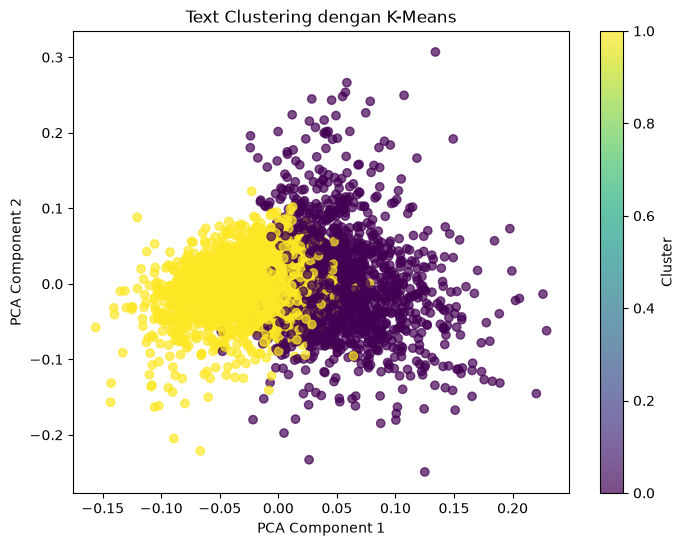

In [7]:
lemmatizer = WordNetLemmatizer()

def clean_text(text):
    text = str(text)
    text = text.lower()
    text = re.sub(r'\d+', '', text)
    text = text.translate(str.maketrans('', '', string.punctuation))
    words = word_tokenize(text)
    words = [lemmatizer.lemmatize(word) for word in words]
    return ' '.join(words)

df['clean_text'] = df['text'].apply(clean_text)

vectorizer = TfidfVectorizer(stop_words='english')
X = vectorizer.fit_transform(df['clean_text'])

num_clusters = 2
kmeans = KMeans(n_clusters=num_clusters, random_state=42, n_init=10)
df['cluster'] = kmeans.fit_predict(X)

pca = PCA(n_components=2)
X_pca = pca.fit_transform(X.toarray())

plt.figure(figsize=(8, 6))
plt.scatter(X_pca[:, 0], X_pca[:, 1], c=df['cluster'], cmap='viridis', alpha=0.7)
plt.xlabel('PCA Component 1')
plt.ylabel('PCA Component 2')
plt.title("Text Clustering dengan K-Means")
plt.colorbar(label='Cluster')
plt.show()

Pada tahap ini saya melakukan seluruh proses klasterisasi, mulai dari membersihkan teks sampai menampilkan hasilnya dalam grafik. Pertama, fungsi clean_text membersihkan sinopsis setiap film. Teks diubah menjadi string terlebih dahulu dengan str(text) sebagai pengaman supaya data yang bukan teks tidak menyebabkan error, lalu huruf dikecilkan semua, angka dan tanda baca dihapus, kalimat dipecah menjadi kata, dan setiap kata dikembalikan ke bentuk dasarnya dengan lemmatization. Hasilnya disimpan di kolom baru bernama clean_text.

Kedua, teks yang sudah bersih diubah menjadi angka dengan TF-IDF. Setiap kata diberi bobot, kata yang khas untuk beberapa film mendapat bobot tinggi dan kata yang muncul di hampir semua film mendapat bobot rendah. Parameter stop_words='english' membuang kata umum seperti the, and, dan of karena tidak membantu membedakan satu film dengan film lain. Hasilnya, setiap sinopsis diwakili oleh deretan angka sehingga bisa dihitung kemiripannya.

Ketiga, K-Means mengelompokkan film ke dalam dua klaster karena num_clusters diatur 2. Algoritma menaruh dua titik pusat, memasukkan setiap film ke pusat yang paling dekat, lalu menggeser pusat ke rata-rata anggotanya, dan proses ini diulang sampai posisinya stabil. Parameter random_state=42 membuat hasilnya sama setiap kali dijalankan, sedangkan n_init=10 membuat algoritma dicoba 10 kali dengan titik awal berbeda lalu diambil yang terbaik. Nomor klaster tiap film (0 atau 1) disimpan di kolom cluster.

Keempat, PCA meringkas data TF-IDF yang dimensinya sangat banyak menjadi dua komponen saja supaya bisa digambar di grafik dua dimensi. Perintah X.toarray() diperlukan karena PCA membutuhkan matriks biasa, bukan matriks sparse hasil TF-IDF. Setiap titik pada grafik mewakili satu film, dan warnanya menunjukkan klaster, ungu untuk klaster 0 dan kuning untuk klaster 1.

Pada grafik terlihat dua kelompok. Kelompok kuning (klaster 1) berada di sisi kiri dan menumpuk rapat di sekitar titik tengah kiri, sedangkan kelompok ungu (klaster 0) berada di sisi kanan dengan sebaran yang lebih lebar dan renggang. Kedua kelompok bertemu dan saling tumpang tindih di sekitar nilai PCA Component 1 antara 0,0 dan 0,05, jadi batas antar klaster tidak benar-benar tegas. Artinya ada cukup banyak film yang sinopsisnya berada di antara dua kelompok sehingga mirip dengan keduanya.

Bentuk sebarannya berupa awan yang menyebar, tidak seperti huruf “L” pada dataset pesan SMS. Menurut saya ini karena sinopsis film lebih panjang dan memuat lebih banyak kata, sehingga variasi antar teksnya lebih beragam. Rentang sumbu grafik juga kecil, sekitar minus 0,15 sampai 0,2, karena nilai TF-IDF memang kecil ketika setiap teks memuat banyak kata.

Dari grafik saja belum bisa dipastikan klaster itu mewakili apa, misalnya genre atau tema cerita tertentu. Untuk memastikan, isi tiap klaster perlu diperiksa dengan melihat kata-kata yang paling dominan di dalamnya. Selain itu, pembagian menjadi dua klaster adalah pilihan yang ditentukan sendiri, sehingga kalau jumlah klaster diubah, hasil pengelompokannya bisa berbeda.